# Spark MLlib — Chicago Crime
Prototype : installation, configuration et manipulation de Spark avec MLlib.

**Objectifs**
1. Charger et explorer ~1M de crimes avec Spark SQL / DataFrame
2. Feature engineering avec MLlib
3. Classification : prédire si un crime mène à une **arrestation** (Logistic Regression vs Random Forest)
4. Clustering : détecter les **zones chaudes** (KMeans sur lat/long)
5. Sauvegarder et recharger les modèles

## 1. Configuration de la SparkSession (PC 16 Go RAM)

In [1]:
import os, time
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("ChicagoCrime-MLlib")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.driver.maxResultSize", "2g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.memory.fraction", "0.7")
         .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark version :", spark.version)
print("Spark UI      :", spark.sparkContext.uiWebUrl)

Spark version : 3.5.3
Spark UI      : http://192.168.1.16:4040


## 2. Chargement des données
- `SOURCE = "csv"` : ton fichier téléchargé (1M lignes) → converti une fois en Parquet
- `SOURCE = "api"` : quelques milliers de lignes via l'API Socrata (démo légère)

In [2]:
SOURCE   = "csv"                          # "csv" ou "api"
CSV_PATH = "data/Crimes.csv"               # <-- chemin de ton fichier
PARQUET  = "data/crimes.parquet"
API_ROWS = 5000

def load_from_api(n):
    import requests, pandas as pd
    url = "https://data.cityofchicago.org/resource/ijzp-q8t2.json"
    params = {"$limit": n, "$where": "latitude IS NOT NULL", "$order": "date DESC",
              "$select": "id,date,primary_type,location_description,arrest,domestic,"
                         "beat,district,ward,community_area,year,latitude,longitude"}
    pdf = pd.DataFrame(requests.get(url, params=params, timeout=120).json()).astype(str)
    return spark.createDataFrame(pdf)

def norm_cols(df):
    # 'Primary Type' -> 'primary_type'
    for c in df.columns:
        df = df.withColumnRenamed(c, c.strip().lower().replace(" ", "_"))
    return df

t = time.time()
if SOURCE == "api":
    raw = norm_cols(load_from_api(API_ROWS))
else:
    if not os.path.exists(PARQUET):
        print("Conversion CSV -> Parquet (une seule fois)...")
        norm_cols(spark.read.csv(CSV_PATH, header=True)).write.mode("overwrite").parquet(PARQUET)
    raw = spark.read.parquet(PARQUET)
print(f"{raw.count():,} lignes chargées en {time.time()-t:.1f}s")
raw.printSchema()

Conversion CSV -> Parquet (une seule fois)...


1,000,000 lignes chargées en 58.4s
root
 |-- id: string (nullable = true)
 |-- date: string (nullable = true)
 |-- primary_type: string (nullable = true)
 |-- location_description: string (nullable = true)
 |-- arrest: string (nullable = true)
 |-- domestic: string (nullable = true)
 |-- beat: string (nullable = true)
 |-- district: string (nullable = true)
 |-- ward: string (nullable = true)
 |-- community_area: string (nullable = true)
 |-- year: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- longitude: string (nullable = true)



## 3. Nettoyage et typage

In [3]:
from pyspark.sql import functions as F

# CSV : 'MM/dd/yyyy hh:mm:ss a' ; API : ISO
date_col = F.coalesce(F.try_to_timestamp(F.col("date"), F.lit("MM/dd/yyyy hh:mm:ss a")),
                      F.try_to_timestamp(F.col("date")))
to_bool = lambda c: F.when(F.lower(F.col(c).cast("string")) == "true", 1).otherwise(0)

df = (raw
      .withColumn("ts", date_col)
      .withColumn("arrest",   to_bool("arrest"))
      .withColumn("domestic", to_bool("domestic"))
      .withColumn("latitude",  F.col("latitude").cast("double"))
      .withColumn("longitude", F.col("longitude").cast("double"))
      .withColumn("district",       F.col("district").cast("double").cast("int"))
      .withColumn("community_area", F.col("community_area").cast("double").cast("int"))
      .dropna(subset=["ts", "latitude", "longitude", "primary_type", "district"])
      .filter((F.col("latitude") > 41) & (F.col("longitude") < -87))   # coordonnées aberrantes
      .withColumn("hour",        F.hour("ts"))
      .withColumn("day_of_week", F.dayofweek("ts"))
      .withColumn("month",       F.month("ts"))
      .withColumn("year",        F.year("ts"))
      .withColumn("is_weekend",  F.col("day_of_week").isin(1, 7).cast("int"))
      .fillna({"location_description": "UNKNOWN"})
      .select("ts","year","month","hour","day_of_week","is_weekend","primary_type",
              "location_description","district","community_area","domestic",
              "latitude","longitude","arrest"))

df.cache()
print(f"{df.count():,} lignes après nettoyage")
df.show(5, truncate=False)

991,557 lignes après nettoyage


+-------------------+----+-----+----+-----------+----------+------------+--------------------+--------+--------------+--------+------------+-------------+------+
|ts                 |year|month|hour|day_of_week|is_weekend|primary_type|location_description|district|community_area|domestic|latitude    |longitude    |arrest|
+-------------------+----+-----+----+-----------+----------+------------+--------------------+--------+--------------+--------+------------+-------------+------+
|2023-09-19 06:50:00|2023|9    |6   |3          |0         |BATTERY     |CTA STATION         |19      |4             |0       |41.966108362|-87.688828331|0     |
|2023-09-19 06:50:00|2023|9    |6   |3          |0         |BATTERY     |SIDEWALK            |11      |23            |0       |41.895502797|-87.71182632 |0     |
|2023-09-19 06:40:00|2023|9    |6   |3          |0         |BATTERY     |SIDEWALK            |10      |30            |0       |41.844262683|-87.723710616|0     |
|2023-09-19 06:40:00|2023|9 

## 4. Exploration (Spark SQL)

In [4]:
df.createOrReplaceTempView("crimes")

spark.sql("""
  SELECT primary_type, COUNT(*) AS n, ROUND(AVG(arrest)*100,1) AS arrest_rate_pct
  FROM crimes GROUP BY primary_type ORDER BY n DESC LIMIT 10
""").show(truncate=False)

print("Taux d'arrestation global :", round(df.agg(F.avg("arrest")).first()[0]*100, 2), "%")

+-------------------+------+---------------+
|primary_type       |n     |arrest_rate_pct|
+-------------------+------+---------------+
|THEFT              |223718|7.2            |
|BATTERY            |174904|17.7           |
|CRIMINAL DAMAGE    |110790|3.9            |
|MOTOR VEHICLE THEFT|88783 |3.0            |
|ASSAULT            |88480 |11.6           |
|OTHER OFFENSE      |64641 |18.1           |
|DECEPTIVE PRACTICE |61770 |3.3            |
|BURGLARY           |38889 |4.7            |
|ROBBERY            |31578 |7.9            |
|WEAPONS VIOLATION  |27240 |65.7           |
+-------------------+------+---------------+



Taux d'arrestation global : 14.18 %


Matplotlib is building the font cache; this may take a moment.


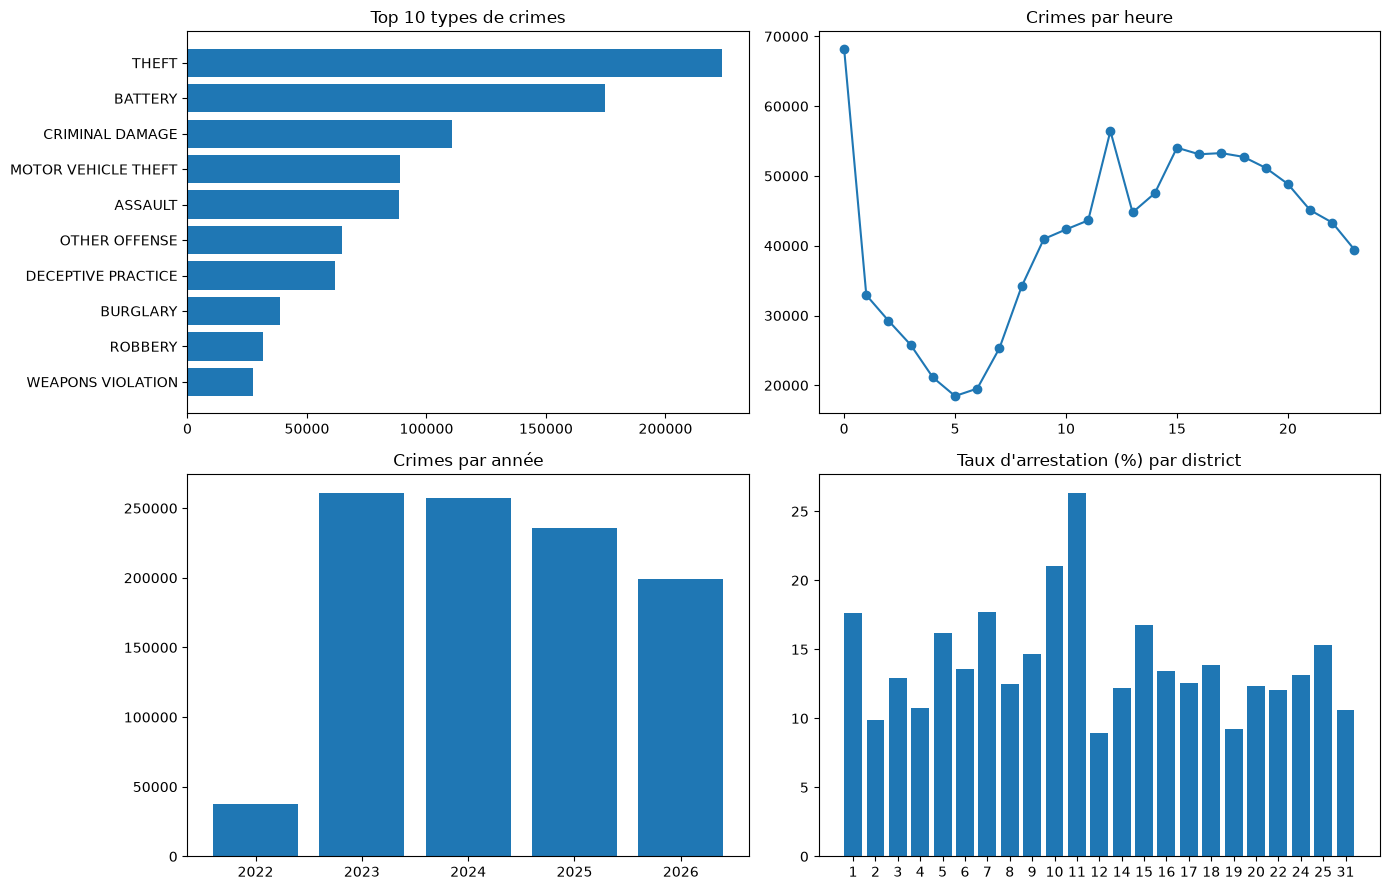

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

top = df.groupBy("primary_type").count().orderBy(F.desc("count")).limit(10).toPandas()
axes[0,0].barh(top["primary_type"][::-1], top["count"][::-1]); axes[0,0].set_title("Top 10 types de crimes")

h = df.groupBy("hour").count().orderBy("hour").toPandas()
axes[0,1].plot(h["hour"], h["count"], marker="o"); axes[0,1].set_title("Crimes par heure")

y = df.groupBy("year").count().orderBy("year").toPandas()
axes[1,0].bar(y["year"], y["count"]); axes[1,0].set_title("Crimes par année")

d = df.groupBy("district").agg(F.avg("arrest").alias("r")).orderBy("district").toPandas()
axes[1,1].bar(d["district"].astype(str), d["r"]*100); axes[1,1].set_title("Taux d'arrestation (%) par district")

plt.tight_layout(); plt.show()

## 5. Pipeline MLlib — classification de l'arrestation
`StringIndexer` → `OneHotEncoder` → `VectorAssembler` → modèle.

Classes déséquilibrées (~10-20 % d'arrestations) → **poids par classe**.

In [6]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

SAMPLE = 1.0          # 0.1 pendant le développement pour itérer vite
data = df.sample(fraction=SAMPLE, seed=42) if SAMPLE < 1 else df

ratio = data.agg(F.avg("arrest")).first()[0]
data = data.withColumn("weight", F.when(F.col("arrest") == 1, 1 - ratio).otherwise(ratio))

train, test = data.randomSplit([0.8, 0.2], seed=42)
train.cache(); test.cache()
print(f"train={train.count():,}  test={test.count():,}")

cat_cols = ["primary_type", "location_description"]
num_cols = ["hour", "day_of_week", "month", "is_weekend", "district",
            "domestic", "latitude", "longitude"]

indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in cat_cols]
encoder  = OneHotEncoder(inputCols=[c+"_idx" for c in cat_cols],
                         outputCols=[c+"_ohe" for c in cat_cols], handleInvalid="keep")
assembler = VectorAssembler(inputCols=[c+"_ohe" for c in cat_cols] + num_cols,
                            outputCol="features", handleInvalid="skip")
prep = indexers + [encoder, assembler]

train=793,154  test=198,403


In [7]:
auc_eval = BinaryClassificationEvaluator(labelCol="arrest", metricName="areaUnderROC")
def evaluate(name, model):
    pred = model.transform(test)
    res = {"model": name, "AUC": auc_eval.evaluate(pred)}
    for m in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
        res[m] = MulticlassClassificationEvaluator(labelCol="arrest", metricName=m).evaluate(pred)
    return res, pred

results = []

# --- Logistic Regression ---
t = time.time()
lr = LogisticRegression(labelCol="arrest", featuresCol="features", weightCol="weight",
                        maxIter=50, regParam=0.01)
lr_model = Pipeline(stages=prep + [lr]).fit(train)
r, lr_pred = evaluate("LogisticRegression", lr_model); r["train_s"] = round(time.time()-t, 1)
results.append(r); print(r)

{'model': 'LogisticRegression', 'AUC': 0.8354555157284095, 'accuracy': 0.7341018028961256, 'f1': 0.7714921546823746, 'weightedPrecision': 0.8625922820560217, 'weightedRecall': 0.7341018028961256, 'train_s': 132.8}


In [8]:
# --- Random Forest (~5-10 min sur 1M lignes) ---
t = time.time()
rf = RandomForestClassifier(labelCol="arrest", featuresCol="features", weightCol="weight",
                            numTrees=50, maxDepth=10, maxBins=64, seed=42)
rf_model = Pipeline(stages=prep + [rf]).fit(train)
r, rf_pred = evaluate("RandomForest", rf_model); r["train_s"] = round(time.time()-t, 1)
results.append(r); print(r)

{'model': 'RandomForest', 'AUC': 0.8350587451298422, 'accuracy': 0.7633705135507024, 'f1': 0.7933423421951296, 'weightedPrecision': 0.8572474333375948, 'weightedRecall': 0.7633705135507023, 'train_s': 251.3}


In [9]:
import pandas as pd
pd.DataFrame(results).set_index("model").round(4)

,AUC,accuracy,f1,weightedPrecision,weightedRecall,train_s
model,,,,,,
LogisticRegression,0.8355,0.7341,0.7715,0.8626,0.7341,132.8
RandomForest,0.8351,0.7634,0.7933,0.8572,0.7634,251.3


### Matrice de confusion et importance des variables (Random Forest)

+------+------+-----+
|arrest|   0.0|  1.0|
+------+------+-----+
|     0|131012|39018|
|     1|  7930|20443|
+------+------+-----+



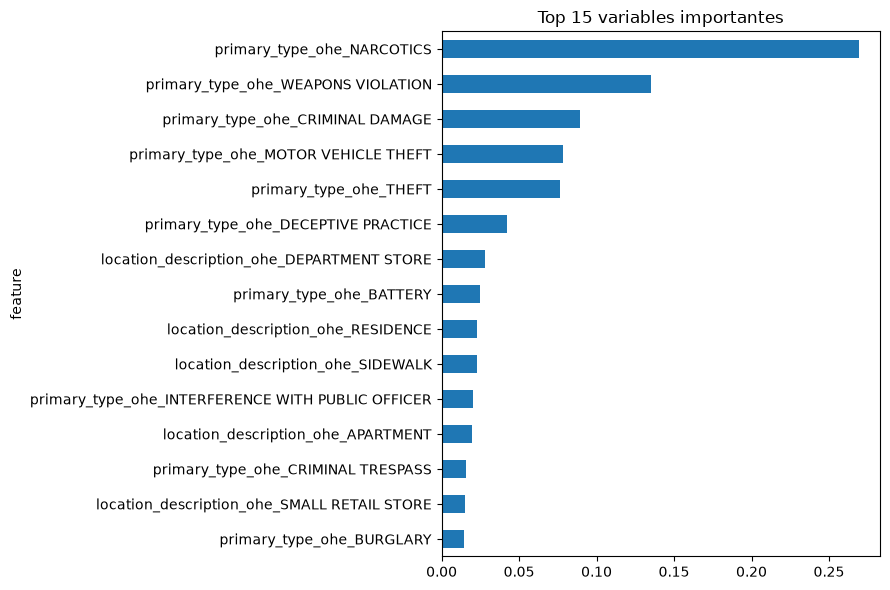

In [10]:
rf_pred.groupBy("arrest").pivot("prediction").count().orderBy("arrest").show()

attrs = rf_pred.schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for group in attrs.values() for a in group}
imp = rf_model.stages[-1].featureImportances.toArray()
fi = (pd.DataFrame({"feature": [names.get(i, str(i)) for i in range(len(imp))], "importance": imp})
        .sort_values("importance", ascending=False).head(15))
ax = fi.plot.barh(x="feature", y="importance", figsize=(9,6), legend=False)
ax.invert_yaxis(); plt.title("Top 15 variables importantes"); plt.tight_layout(); plt.show()

## 6. Tuning (optionnel, ~15-25 min)
`TrainValidationSplit` est ~3x plus rapide que `CrossValidator`.

In [11]:
RUN_TUNING = False
if RUN_TUNING:
    from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
    grid = (ParamGridBuilder()
            .addGrid(rf.numTrees, [30, 60])
            .addGrid(rf.maxDepth, [8, 12])
            .build())
    tvs = TrainValidationSplit(estimator=Pipeline(stages=prep + [rf]),
                               estimatorParamMaps=grid, evaluator=auc_eval,
                               trainRatio=0.8, parallelism=2, seed=42)
    t = time.time()
    tvs_model = tvs.fit(train)
    print(f"Tuning terminé en {time.time()-t:.0f}s")
    print("AUC par combinaison :", [round(m, 4) for m in tvs_model.validationMetrics])
    rf_model = tvs_model.bestModel
    print("Meilleur modèle — AUC test :", auc_eval.evaluate(rf_model.transform(test)))

## 7. Clustering — zones chaudes (KMeans)

In [12]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

geo = VectorAssembler(inputCols=["latitude", "longitude"], outputCol="features").transform(df)

scores = {}
for k in [4, 6, 8, 10]:
    m = KMeans(k=k, seed=42).fit(geo)
    scores[k] = ClusteringEvaluator().evaluate(m.transform(geo))
    print(f"k={k}  silhouette={scores[k]:.4f}")

best_k = max(scores, key=scores.get)
km_model = KMeans(k=best_k, seed=42).fit(geo)
clustered = km_model.transform(geo)
print("k retenu :", best_k)

k=4  silhouette=0.5242


k=6  silhouette=0.5222


k=8  silhouette=0.5010


k=10  silhouette=0.5312


k retenu : 10


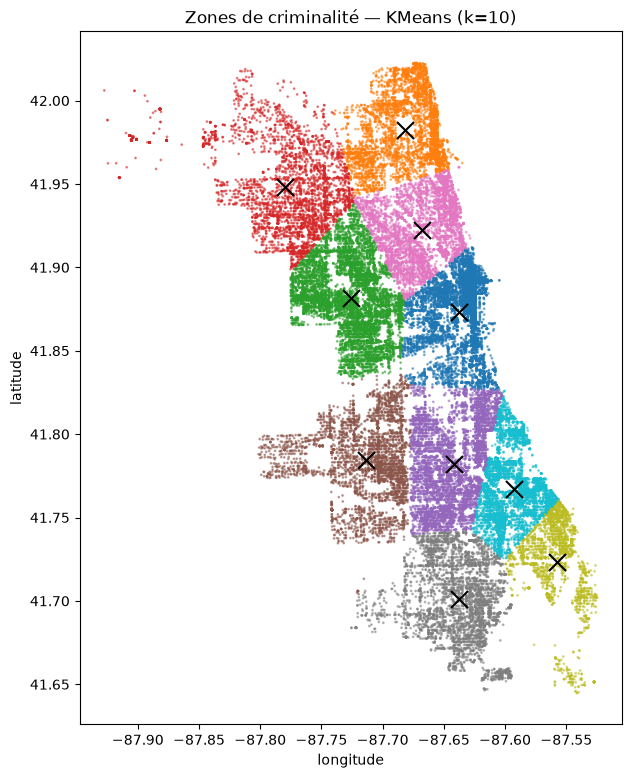

+----------+------+--------+
|prediction|crimes|arrest_%|
+----------+------+--------+
|         0|155223|    14.2|
|         1| 89473|    12.6|
|         2|159929|    20.8|
|         3| 72396|    13.6|
|         4|117560|    15.3|
|         5| 77399|    13.0|
|         6| 97201|     9.2|
|         7| 79928|    14.3|
|         8| 41390|    10.5|
|         9|101058|    11.4|
+----------+------+--------+



In [13]:
frac = min(1.0, 50000 / clustered.count())
pts = clustered.select("latitude","longitude","prediction").sample(frac, seed=1).toPandas()
centers = km_model.clusterCenters()
plt.figure(figsize=(7,9))
plt.scatter(pts["longitude"], pts["latitude"], c=pts["prediction"], s=1, cmap="tab10", alpha=0.5)
plt.scatter([c[1] for c in centers], [c[0] for c in centers], c="black", marker="x", s=150)
plt.title(f"Zones de criminalité — KMeans (k={best_k})"); plt.xlabel("longitude"); plt.ylabel("latitude")
plt.show()

clustered.groupBy("prediction").agg(F.count("*").alias("crimes"),
    F.round(F.avg("arrest")*100,1).alias("arrest_%")).orderBy("prediction").show()

## 8. Sauvegarde et rechargement des modèles (démo live)

In [14]:
lr_model.write().overwrite().save("models/lr_arrest")
rf_model.write().overwrite().save("models/rf_arrest")
km_model.write().overwrite().save("models/kmeans_geo")
print("Modèles sauvegardés dans ./models")

Modèles sauvegardés dans ./models


In [15]:
from pyspark.ml import PipelineModel
loaded = PipelineModel.load("models/rf_arrest")

demo = spark.createDataFrame([
    ("NARCOTICS", "STREET",    22, 6, 7, 1, 11, 0, 41.88, -87.72),
    ("THEFT",     "APARTMENT", 14, 3, 3, 0,  8, 0, 41.77, -87.69),
    ("BATTERY",   "RESIDENCE",  2, 1, 1, 1,  6, 1, 41.75, -87.63),
], ["primary_type","location_description","hour","day_of_week","month",
    "is_weekend","district","domestic","latitude","longitude"])

(loaded.transform(demo)
       .select("primary_type","location_description","hour","prediction","probability")
       .show(truncate=False))

+------------+--------------------+----+----------+----------------------------------------+
|primary_type|location_description|hour|prediction|probability                             |
+------------+--------------------+----+----------+----------------------------------------+
|NARCOTICS   |STREET              |22  |1.0       |[0.17492010934202204,0.8250798906579779]|
|THEFT       |APARTMENT           |14  |0.0       |[0.6933086123539584,0.30669138764604165]|
|BATTERY     |RESIDENCE           |2   |0.0       |[0.5049690009974119,0.495030999002588]  |
+------------+--------------------+----+----------+----------------------------------------+



In [16]:
spark.stop()